# 24 · 预算pacing、约束与整合误差分析

第18章保留总览；本章单独深入一个问题。正式200k实验不覆盖，教学训练使用独立共享记录。

## 先预测：总预算相同，为何投放时段不同？

不加pacing的策略只检查剩余总预算，可能较早花光；均匀pacing进一步约束累计花费≤B×请求进度。它不读取未来点击或true_p，只使用当前请求位置和已花费。后半程流量更有价值是此市场的构造，所以均匀pacing可能有利，也可能在别的市场损失价值。

本章固定seed、价值出价、倍数1和预算60，只切换pacing。用同一潜在市场检查差异，接着验证累计约束，最后把真实点击预测与模拟决策的误差边界连起来。

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'reclab').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from reclab.ads import latest, load_data, split_groups, NUM, CAT, FEATURES
from reclab.paths import ARTIFACTS
from reclab.probability import evaluate
preview=ARTIFACTS/'notebook-previews';preview.mkdir(parents=True,exist_ok=True)
from reclab.auction import market,simulate
synthetic=market(42)
policies={'unpaced':simulate(synthetic,paced=False),'paced':simulate(synthetic,paced=True)}
display(pd.DataFrame([{'policy':name,**{k:r[k] for k in ['spend','wins','clicks','expected_click_value','expected_advertiser_surplus','budget_ok']}} for name,r in policies.items()]))
print('Input probabilities:',synthetic['estimate'].shape,'budgets:',[60]*3)

,policy,spend,wins,clicks,expected_click_value,expected_advertiser_surplus,budget_ok
0,unpaced,179.950958,1654,193,325.099130,145.148171,True
1,paced,179.352946,2522,181,363.687988,184.335042,True


Input probabilities: (6000, 3) budgets: [60, 60, 60]


## 约束是逐请求不变量，不是终点检查

仅检查最终花费≤预算，会漏掉先超支再修正等错误。实现中每次成交都验证payment≤bid，每次请求后验证累计花费≤总预算；pacing开启时还验证≤时间释放预算。曲线按20个检查点展示，内部断言实际覆盖全部6000请求。

先预测：unpaced曲线会在哪个时段接近预算上限？看图后解释它与后半程价值构造的关系。

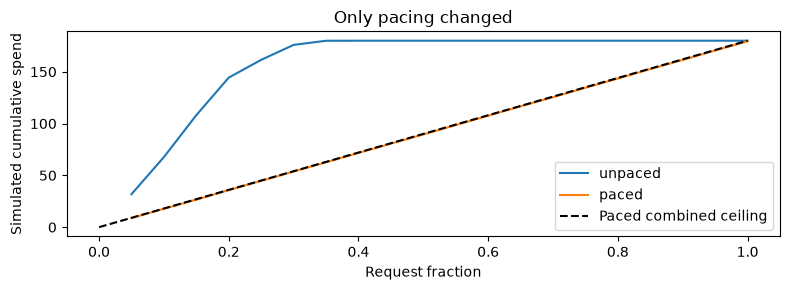

In [2]:
fig,ax=plt.subplots(figsize=(8,3))
for name,r in policies.items():
 t=np.array([x['fraction'] for x in r['trace']]);spend=np.array([x['spend'] for x in r['trace']])
 assert (spend<=60+1e-8).all()
 if name=='paced':assert (spend<=60*t[:,None]+1e-8).all()
 ax.plot(t,spend.sum(axis=1),label=name)
ax.plot([0,1],[0,180],'k--',label='Paced combined ceiling')
ax.set(xlabel='Request fraction',ylabel='Simulated cumulative spend',title='Only pacing changed');ax.legend();fig.tight_layout();fig.savefig(preview/'24_pacing.png',dpi=130);plt.show()

## 只改一个变量：更紧的预算

pacing固定开启，预算从60降到30；市场、倍数与策略不变。更低预算不保证点击价值按比例下降，因为资格和竞争路径会改变。每个广告主必须单独满足预算，不能用总花费抵消某个广告主超支。

本格实际重新执行模拟，不读取预先写好的表。练习再将budget设为10，记录丢失曝光、花费与价值，解释为什么这不是模型AUC变化。

In [3]:
budget=30.  # Exercise: change only this value to 10.
tight=simulate(synthetic,budget=budget,paced=True)
display(pd.DataFrame(tight['advertisers']))
assert all(r['spend']<=budget+1e-8 for r in tight['advertisers'])
assert all(max(t['spend'])<=budget*t['fraction']+1e-8 for t in tight['trace'])
print('Tighter budget:',{k:tight[k] for k in ['spend','wins','expected_click_value','budget_ok']})

,spend,wins,clicks
0,29.842661,508,31
1,29.837349,489,27
2,29.819974,453,28


Tighter budget: {'spend': 89.49998375283522, 'wins': 1450, 'expected_click_value': 173.46772010420707, 'budget_ok': True}


## 整合误差链：预测分数到资格，再到支付

真实任务告诉我们某个样本分布上模型是否能区分点击、概率是否接近真实频率；它没有竞价者、底价、预算与propensity。模拟任务告诉我们给定这些假设时的资源分配，不是对真实Criteo做off-policy评估。

先预测：把估计概率放大1.5但保持真实概率与潜在点击不变，预算会不会自动违规？约束必须始终有效；价值和成交分配却可能改变。这是明确的模拟预测偏差压力测试，不是对真实CTR的校准估计。

In [4]:
biased={**synthetic,'estimate':np.clip(synthetic['estimate']*1.5,.001,.99)}
bias_run=simulate(biased,paced=True)
assert bias_run['budget_ok']
display(pd.DataFrame([{'prediction':name,**{k:r[k] for k in ['spend','wins','expected_click_value','expected_advertiser_surplus','budget_ok']}} for name,r in [('original',policies['paced']),('overestimated',bias_run)]]))
print('Only synthetic estimated probabilities changed; true probabilities and potential clicks are shared.')

,prediction,spend,wins,expected_click_value,expected_advertiser_surplus,budget_ok
0,original,179.352946,2522,363.687988,184.335042,True
1,overestimated,179.076553,2366,277.435022,98.358469,True


Only synthetic estimated probabilities changed; true probabilities and potential clicks are shared.


## 回到同一系统：分层验收与下一步

数据层：真实曝光标签、固定来源、哈希、训练边界；预测层：真实训练、select选型、独立calibration、保留audit负结果；决策层：模拟假设、支付与预算不变量。三个领域共用实验生命周期与工作台，不共享不适用的标签和指标。

下面确认教学运行没有替换正式ads run，再读取其预定分段与校准不确定性。练习写一份失败诊断：哪一项是观测证据，哪一项是假设，下一步需要什么新数据？禁止把NDCG、AUC和模拟收入放成一个可比较排行榜。

In [5]:
from reclab.experiments import catalog
receipt,result=latest()
print('Formal 200k run:',receipt['run_id'])
print('Workshop records:',[(r['run_id'],r['config']['workshop'],r['state']) for r in catalog() if r['domain']=='ads' and r['config'].get('workshop')])
display(pd.DataFrame([{'segment':s['segment'],'n':s['raw']['n'],'CTR':s['raw']['click_rate'],'raw_logloss':s['raw']['logloss'],'sigmoid_logloss':s['sigmoid']['logloss']} for s in result['segments']]))
print(result['paired_sigmoid'])
print('Acceptance: budget invariants passed; real and synthetic claims remain separated; negative model/calibration results retained.')

Formal 200k run: 20261030T125738-f82b6582
Workshop records: [('20261030T130907-22ac6037', 'linear_features', 'completed'), ('20261030T130911-14b5a3de', 'tree_capacity', 'completed')]


,segment,n,CTR,raw_logloss,sigmoid_logloss
0,low_numeric_missing,17016,0.036495,0.147043,0.146935
1,high_numeric_missing,12912,0.028733,0.121515,0.121515
2,any_unseen_category,11668,0.035996,0.146929,0.146712
3,all_categories_seen,18260,0.031325,0.129065,0.129103


{'calibrated_minus_raw_logloss': -6.130390957040765e-05, 'iid_row_bootstrap_95': [-0.00016953362229380587, 6.253575759107997e-05], 'replicates': 300, 'limitation': 'conditional on fitted models; repeated/related rows and one shard limit independence and generalization'}
Acceptance: budget invariants passed; real and synthetic claims remain separated; negative model/calibration results retained.
